# GamePulse Review Sentiment with PyTorch

A reproducible binary sentiment-classification experiment using video game reviews. The dataset combines AI-assigned Steam labels and Xbox star-rating proxies, so results should be interpreted cautiously.

## Project Description

This notebook uses review text to train a PyTorch multilayer perceptron (MLP) to distinguish positive from negative player reviews. It compares a baseline model with a tuned version, evaluates both on held-out reviews, and inspects individual predictions.

## Real-World Problem

Game reviews are numerous and can be difficult to summarize. A sentiment estimate can help players scan overall reactions, but it can also misrepresent sarcasm, mixed feedback, or communities underrepresented in the data. The model is a learning demonstration and should not replace reading the underlying reviews.

## Project Objective

Train and compare two PyTorch MLP models that classify game review text as positive or negative, evaluate their performance on held-out reviews, and examine example predictions and limitations.

## Dataset

The included GamePulse validation sample has review text and sentiment labels from Steam and Xbox written reviews. Steam labels were AI-assigned and not human verified; Xbox labels derive from star ratings and are only proxies for text sentiment. Neutral and mixed labels are excluded from this binary positive-versus-negative task. Review IDs and platform IDs were removed from the included copy.

## Import Libraries

In [2]:
from copy import deepcopy
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

ImportError: `torch` can only be initialized once per process, so this module cannot be imported again: neither via `importlib.reload(torch)`, nor by re-importing after a failed `import torch`.

## Load the Dataset

In [2]:
DATA_PATH = Path("data") / "gamepulse_sentiment_validation_sample.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Could not find {DATA_PATH}. Run this notebook from the project folder.")

reviews = pd.read_csv(DATA_PATH)
print(f"Loaded {len(reviews):,} rows and {len(reviews.columns)} columns")
reviews.head(3)

Loaded 1,100 rows and 5 columns


,game_name,review_date,review_text,manual_sentiment_label,annotation_notes
0,ENA: Dream BBQ,2026-01-05,acid trip the game. beautifully done. even whe...,positive,AI-assigned label (Copilot); not human-verified
1,Battlefield™ 6,2026-08-09,So apparently Battlefield 6 devs have silently...,negative,AI-assigned label (Copilot); not human-verified
2,ENA: Dream BBQ,2026-10-05,ENA: Dream BBQ feels like wandering through a ...,positive,AI-assigned label (Copilot); not human-verified


## Explore and Prepare the Data

Keep only positive and negative labels for this binary experiment. Neutral and mixed reviews are excluded rather than forced into a class. Split the text before fitting TF-IDF so vocabulary selection cannot see validation or test text.

In [3]:
reviews["label"] = reviews["manual_sentiment_label"].astype("string").str.strip().str.lower()
reviews["review_text"] = reviews["review_text"].astype("string").str.strip()
reviews = reviews.dropna(subset=["review_text", "label"])
reviews = reviews[reviews["review_text"].ne("") & reviews["label"].isin(["positive", "negative"])].copy()
reviews = reviews.drop_duplicates(subset=["review_text"]).reset_index(drop=True)

label_to_id = {"negative": 0, "positive": 1}
texts = reviews["review_text"].astype(str)
labels = reviews["label"].map(label_to_id).astype("int64")
print("Usable binary examples:", len(reviews))
print(reviews["label"].value_counts())

Usable binary examples: 783
label
positive    461
negative    322
Name: count, dtype: Int64


## Create DataLoaders

The split is stratified by target label: 68% train, 12% validation, and 20% test. Validation guides epoch selection; the test set is held back for the final comparison.

In [4]:
train_val_text, test_text, train_val_y, test_y = train_test_split(
    texts, labels, test_size=0.20, random_state=SEED, stratify=labels
)
train_text, val_text, train_y, val_y = train_test_split(
    train_val_text, train_val_y, test_size=0.15, random_state=SEED, stratify=train_val_y
)

vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=3000, min_df=2, sublinear_tf=True)
x_train = vectorizer.fit_transform(train_text).toarray().astype(np.float32)
x_val = vectorizer.transform(val_text).toarray().astype(np.float32)
x_test = vectorizer.transform(test_text).toarray().astype(np.float32)

def make_dataset(features, targets):
    return TensorDataset(torch.tensor(features, dtype=torch.float32), torch.tensor(targets.to_numpy(), dtype=torch.float32))

BATCH_SIZE = 32
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(make_dataset(x_train, train_y), batch_size=BATCH_SIZE, shuffle=True, generator=loader_generator)
val_loader = DataLoader(make_dataset(x_val, val_y), batch_size=BATCH_SIZE, shuffle=False)
print(f"Train: {len(train_y)} | validation: {len(val_y)} | test: {len(test_y)} | TF-IDF features: {x_train.shape[1]}")

Train: 532 | validation: 94 | test: 157 | TF-IDF features: 3000


## Define the PyTorch Model

The network is a feed-forward MLP. TF-IDF values form the input layer; a fully connected hidden layer uses ReLU, optional dropout, and a single logit output for binary polarity. `BCEWithLogitsLoss` combines the sigmoid operation with binary cross-entropy for stable training.

In [5]:
class ReviewSentimentMLP(nn.Module):
    def __init__(self, input_features, hidden_units=32, dropout=0.0):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_features, hidden_units),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_units, 1),
        )

    def forward(self, features):
        return self.network(features).squeeze(1)

## Select the Loss Function and Optimizer

Both experiments use binary cross-entropy with logits, Adam, learning rate 0.001, batch size 32, and 15 epochs. The updated network changes the hidden width and adds dropout. Validation loss selects the retained epoch; test examples are not used for training or selection.

In [6]:
LEARNING_RATE = 0.001
EPOCHS = 15
criterion = nn.BCEWithLogitsLoss()

## Train the Original Model

Baseline: 32 hidden units and no dropout.

In [8]:
def train_model(hidden_units, dropout, seed=SEED):
    torch.manual_seed(seed)
    model = ReviewSentimentMLP(x_train.shape[1], hidden_units=hidden_units, dropout=dropout).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {"train_loss": [], "val_loss": [], "train_accuracy": [], "val_accuracy": []}
    best_state = None
    best_val_loss = float("inf")

    for epoch in range(EPOCHS):
        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        train_count = 0
        for features, targets in train_loader:
            features, targets = features.to(DEVICE), targets.to(DEVICE)
            optimizer.zero_grad()
            logits = model(features)
            loss = criterion(logits, targets)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(targets)
            train_correct += ((torch.sigmoid(logits) >= 0.5) == (targets >= 0.5)).sum().item()
            train_count += len(targets)

        model.eval()
        val_loss_sum = 0.0
        val_correct = 0
        val_count = 0
        with torch.no_grad():
            for features, targets in val_loader:
                features, targets = features.to(DEVICE), targets.to(DEVICE)
                logits = model(features)
                val_loss_sum += criterion(logits, targets).item() * len(targets)
                val_correct += ((torch.sigmoid(logits) >= 0.5) == (targets >= 0.5)).sum().item()
                val_count += len(targets)

        train_loss = train_loss_sum / train_count
        val_loss = val_loss_sum / val_count
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_correct / train_count)
        history["val_accuracy"].append(val_correct / val_count)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = deepcopy(model.state_dict())
        print(f"Epoch {epoch + 1:02d}/{EPOCHS} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val accuracy {val_correct / val_count:.3f}")

    model.load_state_dict(best_state)
    return model, history

original_model, original_history = train_model(hidden_units=32, dropout=0.0)

Epoch 01/15 | train loss 0.6833 | val loss 0.6816 | val accuracy 0.585
Epoch 02/15 | train loss 0.6707 | val loss 0.6729 | val accuracy 0.585
Epoch 03/15 | train loss 0.6501 | val loss 0.6583 | val accuracy 0.585
Epoch 04/15 | train loss 0.6166 | val loss 0.6387 | val accuracy 0.660
Epoch 05/15 | train loss 0.5723 | val loss 0.6146 | val accuracy 0.681
Epoch 06/15 | train loss 0.5207 | val loss 0.5872 | val accuracy 0.755
Epoch 07/15 | train loss 0.4665 | val loss 0.5633 | val accuracy 0.766
Epoch 08/15 | train loss 0.4129 | val loss 0.5354 | val accuracy 0.787
Epoch 09/15 | train loss 0.3622 | val loss 0.5132 | val accuracy 0.798
Epoch 10/15 | train loss 0.3159 | val loss 0.4926 | val accuracy 0.777
Epoch 11/15 | train loss 0.2751 | val loss 0.4730 | val accuracy 0.777
Epoch 12/15 | train loss 0.2396 | val loss 0.4579 | val accuracy 0.798
Epoch 13/15 | train loss 0.2092 | val loss 0.4467 | val accuracy 0.787
Epoch 14/15 | train loss 0.1830 | val loss 0.4353 | val accuracy 0.787
Epoch 

## Evaluate the Original Model

In [9]:
def predict_labels(model, features):
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(features, dtype=torch.float32, device=DEVICE))
        probabilities = torch.sigmoid(logits).cpu().numpy()
    return (probabilities >= 0.5).astype(int), probabilities

def evaluate_model(model, features, targets):
    predicted, probabilities = predict_labels(model, features)
    truth = targets.to_numpy()
    return {
        "accuracy": accuracy_score(truth, predicted),
        "precision": precision_score(truth, predicted, zero_division=0),
        "recall": recall_score(truth, predicted, zero_division=0),
        "f1": f1_score(truth, predicted, zero_division=0),
    }, predicted, probabilities

original_metrics, original_predictions, original_probabilities = evaluate_model(original_model, x_test, test_y)
print("Original model held-out test metrics")
print(pd.Series(original_metrics).round(3))
print(classification_report(test_y, original_predictions, target_names=["negative", "positive"], zero_division=0))

Original model held-out test metrics
accuracy     0.790
precision    0.781
recall       0.891
f1           0.832
dtype: float64
              precision    recall  f1-score   support

    negative       0.81      0.65      0.72        65
    positive       0.78      0.89      0.83        92

    accuracy                           0.79       157
   macro avg       0.79      0.77      0.78       157
weighted avg       0.79      0.79      0.79       157



## Fine-Tune or Optimize the Model

Updated model: increase the hidden layer from 32 to 64 units and add 30% dropout. This tests whether added capacity with regularization changes generalization. The same data split, vectorizer, training schedule, optimizer, and loss are used.

In [10]:
tuned_model, tuned_history = train_model(hidden_units=64, dropout=0.30)

Epoch 01/15 | train loss 0.6834 | val loss 0.6804 | val accuracy 0.585
Epoch 02/15 | train loss 0.6671 | val loss 0.6687 | val accuracy 0.585
Epoch 03/15 | train loss 0.6388 | val loss 0.6490 | val accuracy 0.596
Epoch 04/15 | train loss 0.5955 | val loss 0.6230 | val accuracy 0.681
Epoch 05/15 | train loss 0.5396 | val loss 0.5920 | val accuracy 0.702
Epoch 06/15 | train loss 0.4734 | val loss 0.5566 | val accuracy 0.766
Epoch 07/15 | train loss 0.4083 | val loss 0.5252 | val accuracy 0.787
Epoch 08/15 | train loss 0.3444 | val loss 0.4938 | val accuracy 0.798
Epoch 09/15 | train loss 0.2915 | val loss 0.4712 | val accuracy 0.777
Epoch 10/15 | train loss 0.2437 | val loss 0.4499 | val accuracy 0.809
Epoch 11/15 | train loss 0.2067 | val loss 0.4332 | val accuracy 0.809
Epoch 12/15 | train loss 0.1732 | val loss 0.4226 | val accuracy 0.809
Epoch 13/15 | train loss 0.1464 | val loss 0.4163 | val accuracy 0.777
Epoch 14/15 | train loss 0.1248 | val loss 0.4074 | val accuracy 0.798
Epoch 

## Evaluate the Updated Model

In [11]:
tuned_metrics, tuned_predictions, tuned_probabilities = evaluate_model(tuned_model, x_test, test_y)
print("Updated model held-out test metrics")
print(pd.Series(tuned_metrics).round(3))
print(classification_report(test_y, tuned_predictions, target_names=["negative", "positive"], zero_division=0))

Updated model held-out test metrics
accuracy     0.803
precision    0.796
recall       0.891
f1           0.841
dtype: float64
              precision    recall  f1-score   support

    negative       0.81      0.68      0.74        65
    positive       0.80      0.89      0.84        92

    accuracy                           0.80       157
   macro avg       0.81      0.78      0.79       157
weighted avg       0.80      0.80      0.80       157



In the saved test results, the updated model's main strength is recognizing positive reviews: its positive-class recall is 0.89 and F1 is 0.84. It also identifies 68% of negative reviews, compared with 65% for the original model. However, its lower negative-class recall means it misses about one-third of negative reviews. These observations apply to this small held-out sample, whose labels are AI-assigned or rating-based proxies, rather than proving performance on other reviews.

## Compare the Results

A lower validation loss selects an epoch; held-out test metrics estimate performance on this sample. A change can help, have little effect, or hurt. Interpret small differences cautiously because the sample is limited and labels are noisy.

In [12]:
comparison = pd.DataFrame([{"model": "Original: 32 units, no dropout", **original_metrics},
                           {"model": "Updated: 64 units, 30% dropout", **tuned_metrics}])
comparison.round(3)

,model,accuracy,precision,recall,f1
0,"Original: 32 units, no dropout",0.790,0.781,0.891,0.832
1,"Updated: 64 units, 30% dropout",0.803,0.796,0.891,0.841


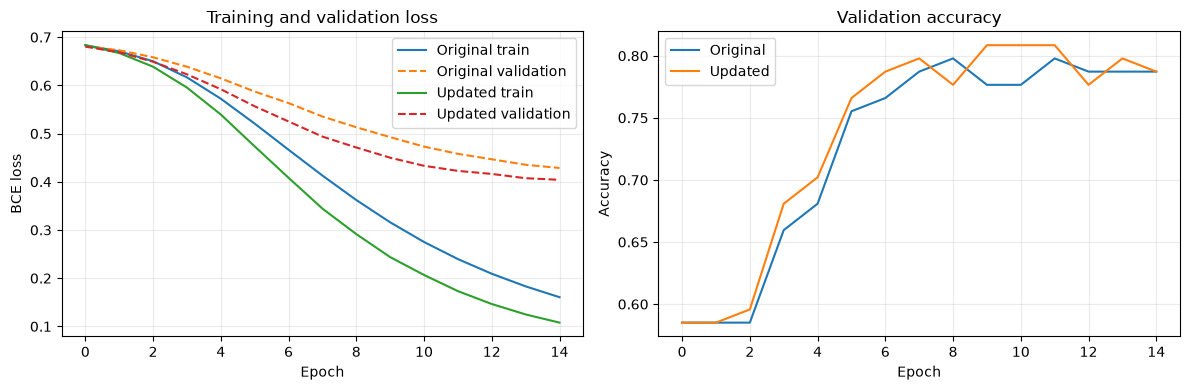

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in [("Original", original_history), ("Updated", tuned_history)]:
    axes[0].plot(history["train_loss"], label=f"{name} train")
    axes[0].plot(history["val_loss"], linestyle="--", label=f"{name} validation")
    axes[1].plot(history["val_accuracy"], label=name)
axes[0].set(title="Training and validation loss", xlabel="Epoch", ylabel="BCE loss")
axes[1].set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Example Predictions

Show held-out inputs with the actual label, model prediction, and estimated positive probability. Include a misclassified example when one exists, then show correct predictions to provide context.

In [13]:
correct_mask = tuned_predictions == test_y.to_numpy()
correct_indices = np.flatnonzero(correct_mask)
incorrect_indices = np.flatnonzero(~correct_mask)
selected_indices = incorrect_indices[:1].tolist()
selected_indices.extend(correct_indices[:3 - len(selected_indices)].tolist())
if len(selected_indices) < 3:
    selected_indices.extend(incorrect_indices[1:1 + 3 - len(selected_indices)].tolist())
examples = pd.DataFrame({"review_text": test_text.iloc[selected_indices].to_numpy(),
                         "actual": test_y.iloc[selected_indices].map({0: "negative", 1: "positive"}).to_numpy(),
                         "predicted": pd.Series(tuned_predictions[selected_indices]).map({0: "negative", 1: "positive"}).to_numpy(),
                         "positive_probability": tuned_probabilities[selected_indices]})
examples["correct"] = examples["actual"] == examples["predicted"]
for _, row in examples.iterrows():
    print(f"Actual: {row.actual} | Predicted: {row.predicted} | P(positive): {row.positive_probability:.3f} | Correct: {row.correct}")
    print(row.review_text)
    print()
if len(incorrect_indices):
    print("Included a misclassified example because one is available in the held-out test set.")
else:
    print("No misclassified examples were found in the held-out test set.")

Actual: positive | Predicted: negative | P(positive): 0.367 | Correct: False
This hopefully marks a clear intent to remake all DQ upto 8 as the people begging for it are putting their wallets in with pre orders

Actual: positive | Predicted: positive | P(positive): 0.928 | Correct: True
its really fun and plus its free

Actual: positive | Predicted: positive | P(positive): 0.854 | Correct: True
Usually simple coop games like this offers only less than 10 hours playtime and once finish we never touch again, but this game is gold. Devs keep releasing new updates and its also fun to replay.

Included a misclassified example because one is available in the held-out test set.


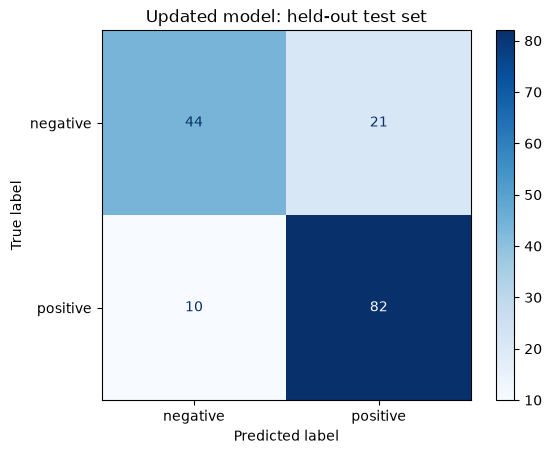

In [15]:
ConfusionMatrixDisplay.from_predictions(test_y, tuned_predictions, display_labels=["negative", "positive"], cmap="Blues")
plt.title("Updated model: held-out test set")
plt.show()

## Ethical Considerations

The Steam labels were AI-assigned and the Xbox labels are star-rating proxies, so each can encode mistakes or disagreement between a rating and the text. Data may not represent every language, platform, or player community. The classifier can misread sarcasm and mixed reviews. Its score should be shown as an uncertain summary and not used to judge individual reviewers.

## Societal Impact

A potential benefit is helping players navigate a large volume of feedback before spending time or money on a game. A possible harm is that inaccurate summaries could unfairly affect a game's reputation or drown out smaller groups of reviewers. Keeping source reviews accessible and being transparent about the labels can reduce, but not remove, that risk.

## Conclusion

On the 157-review held-out test set, the baseline MLP achieved 79.0% accuracy and an F1 score of 0.832. The updated model, with 64 hidden units and 30% dropout, achieved 80.3% accuracy and an F1 score of 0.841, with the same 89.1% recall. This is a modest improvement on this sample and suggests the tuning change was helpful here, but it does not establish that the updated model will perform better on other reviews.

This project demonstrates that a PyTorch MLP using TF-IDF text features can learn a useful positive-versus-negative signal from game reviews. The results are limited by the small dataset and noisy labels: Steam labels were AI-assigned and Xbox labels are rating-based proxies for written sentiment. The random review split may also place reviews of the same game in both training and test sets, so performance on entirely unseen games is unknown. The model should be treated as an educational experiment and rough review-summary aid, not as a reliable substitute for human interpretation.